# META-SGD Model

# Ablation Study

Running on CPU  |  Seed: 11

Upload 3 CSV files: train (augmented), validation, test


Saving test_set_scaled.csv to test_set_scaled (1).csv
Saving validation_set_scaled.csv to validation_set_scaled (1).csv
Saving preprocessed_augmented_dataset_scaled.csv to preprocessed_augmented_dataset_scaled (1).csv
Train: preprocessed_augmented_dataset_scaled (1).csv
Val:   validation_set_scaled (1).csv
Test:  test_set_scaled (1).csv

Features: 19  |  Classes: 10
Train: 100000  Val: 320  Test: 330

Running variant: 0_baseline


Epoch 1/3:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 2/3:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 3/3:   0%|          | 0/782 [00:00<?, ?it/s]

  -> Test Acc: 0.9333 | F1: 0.9326 | Params: 106,826

Running variant: 1_no_label_smooth


... (36 outputs left out)

Epoch 1/3:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 2/3:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 3/3:   0%|          | 0/782 [00:00<?, ?it/s]

  -> Test Acc: 0.9333 | F1: 0.9325 | Params: 106,826

ABLATION STUDY RESULTS (sorted by F1)
              variant  test_acc  test_prec  test_rec  test_f1  params
         4_no_dropout  0.942424   0.942369  0.942424 0.941895  106826
    1_no_label_smooth  0.936364   0.936861  0.936364 0.935629  106826
       2_no_grad_clip  0.936364   0.937006  0.936364 0.935510  106826
3_no_weighted_sampler  0.936364   0.937006  0.936364 0.935510  106826
     8_higher_dropout  0.936364   0.935037  0.936364 0.934418  106826
       7_single_layer  0.933333   0.935547  0.933333 0.932770   39882
          6_two_heads  0.933333   0.935527  0.933333 0.932741  106826
           0_baseline  0.933333   0.933653  0.933333 0.932556  106826
         10_higher_lr  0.933333   0.932946  0.933333 0.932476  106826
    5_smaller_d_model  0.930303   0.929590  0.930303 0.927505   27818
           9_lower_lr  0.903030   0.899779  0.903030 0.899688  106826

Saved: meta_sgd_ablation_results.csv


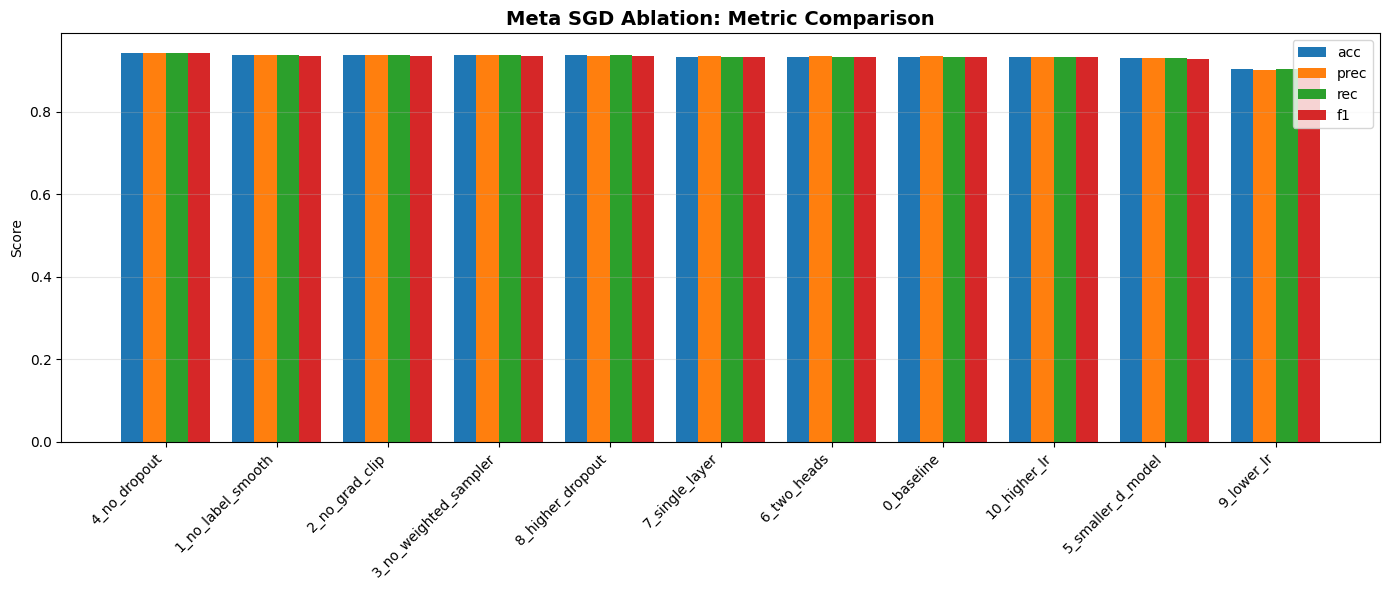

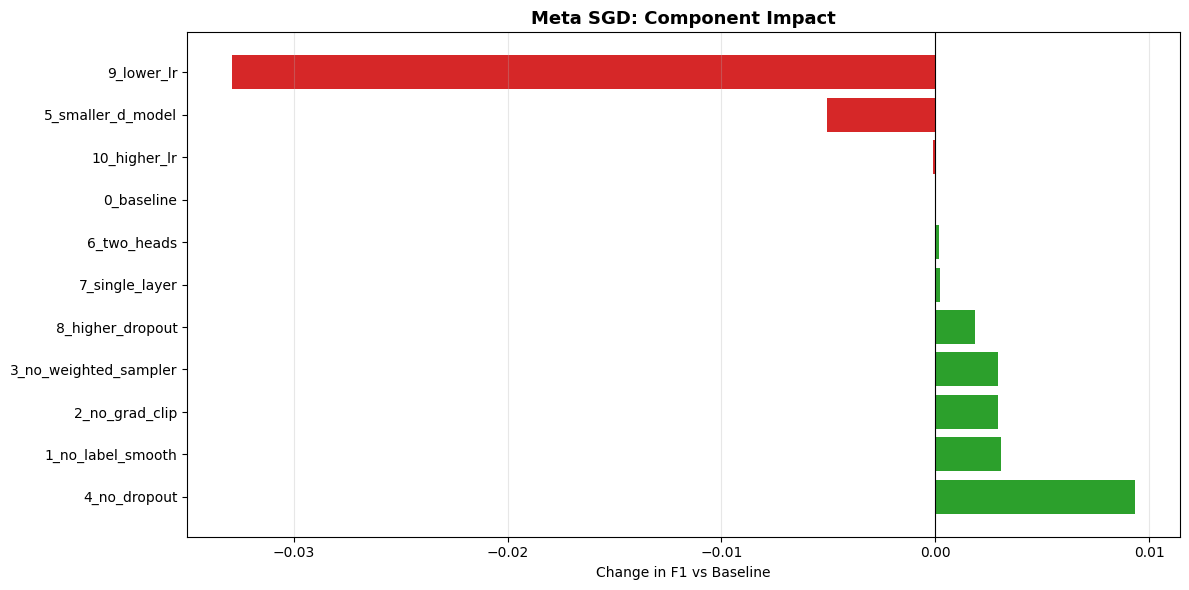


Saved plots: meta_sgd_ablation_metrics.png, meta_sgd_ablation_delta.png

SUMMARY: F1 delta vs baseline
              variant  f1_delta  params
           9_lower_lr -0.032868  106826
    5_smaller_d_model -0.005051   27818
         10_higher_lr -0.000080  106826
          6_two_heads  0.000185  106826
       7_single_layer  0.000214   39882
     8_higher_dropout  0.001862  106826
       2_no_grad_clip  0.002954  106826
3_no_weighted_sampler  0.002954  106826
    1_no_label_smooth  0.003073  106826
         4_no_dropout  0.009339  106826


In [ ]:
# ============================================================
# ABLATION STUDY: META-SGD TRANSFORMER FOR BEARING FAULT DETECTION
# Variants tested:
#   0. Full model (baseline)
#   1. No Label Smoothing
#   2. No Gradient Clipping
#   3. No Weighted Sampler (class imbalance handling removed)
#   4. No Dropout
#   5. Smaller Embedding Dimension (d_model: 64 → 32)
#   6. Two Attention Heads instead of Four
#   7. Single Transformer Encoder Layer instead of Three
#   8. Higher Dropout (0.15 → 0.30)
#   9. Lower Learning Rate (3e-4 → 1e-4)
#  10. Higher Learning Rate (3e-4 → 1e-3)
# ============================================================
# ============================================================

# !pip -q install torch pandas numpy scikit-learn tqdm matplotlib

import copy
import random
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm
from google.colab import files

warnings.filterwarnings('ignore')

# ============================================================
# 1. CONFIGURATION
# ============================================================
TARGET_COL   = "fault_encoded"
SEED         = 11
D_MODEL      = 64
N_HEADS      = 4
N_LAYERS     = 3
DROPOUT      = 0.15
BATCH_SIZE   = 128
EPOCHS       = 4          # reduced for ablation speed
PATIENCE     = 4           # reduced for ablation speed
LR           = 3e-4
LR_MIN       = 1e-6
WEIGHT_DECAY = 3e-4
LABEL_SMOOTH = 0.08
GRAD_CLIP    = 2.0

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)
DEVICE = torch.device("cpu")
print(f"Running on CPU  |  Seed: {SEED}")

# ============================================================
# 2. DATA LOADING
# ============================================================
print("\nUpload 3 CSV files: train (augmented), validation, test")
uploaded = files.upload()
names    = list(uploaded.keys())

def pick(role):
    kw = {
        "train": ["augmented", "train", "training", "preprocessed"],
        "val":   ["val", "validation"],
        "test":  ["test"],
    }
    hits = [f for f in names if any(k in f.lower() for k in kw[role])]
    if len(hits) == 1:
        return hits[0]
    for i, f in enumerate(names):
        print(f"  {i}: {f}")
    return names[int(input(f"Enter index for {role} file: "))]

train_file, val_file, test_file = pick("train"), pick("val"), pick("test")
print(f"Train: {train_file}\nVal:   {val_file}\nTest:  {test_file}")

train_df = pd.read_csv(train_file)
val_df   = pd.read_csv(val_file)
test_df  = pd.read_csv(test_file)

if TARGET_COL not in train_df.columns:
    print("Available columns:", list(train_df.columns))
    TARGET_COL = input("Enter target column name: ")

feat_cols = [c for c in train_df.columns if c != TARGET_COL]

for df in [train_df, val_df, test_df]:
    df[feat_cols] = df[feat_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

le = LabelEncoder()
le.fit(pd.concat([train_df[TARGET_COL], val_df[TARGET_COL], test_df[TARGET_COL]]))

X_tr = train_df[feat_cols].values.astype(np.float32)
y_tr = le.transform(train_df[TARGET_COL])
X_va = val_df[feat_cols].values.astype(np.float32)
y_va = le.transform(val_df[TARGET_COL])
X_te = test_df[feat_cols].values.astype(np.float32)
y_te = le.transform(test_df[TARGET_COL])

n_feat    = X_tr.shape[1]
n_classes = len(le.classes_)
print(f"\nFeatures: {n_feat}  |  Classes: {n_classes}")
print(f"Train: {len(X_tr)}  Val: {len(X_va)}  Test: {len(X_te)}")

scaler  = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_va_sc = scaler.transform(X_va)
X_te_sc = scaler.transform(X_te)

def to_t(X, y):
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

X_tr_t, y_tr_t = to_t(X_tr_sc, y_tr)
X_va_t, y_va_t = to_t(X_va_sc, y_va)
X_te_t, y_te_t = to_t(X_te_sc, y_te)

cw_np = compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
sw = torch.tensor(cw_np[y_tr], dtype=torch.float32)
sampler = WeightedRandomSampler(sw, len(sw), replacement=True)

def get_loaders(batch_size):
    train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=batch_size, sampler=sampler, num_workers=0)
    val_loader   = DataLoader(TensorDataset(X_va_t, y_va_t), batch_size=batch_size, shuffle=False,  num_workers=0)
    test_loader  = DataLoader(TensorDataset(X_te_t, y_te_t), batch_size=batch_size, shuffle=False,  num_workers=0)
    return train_loader, val_loader, test_loader

# ============================================================
# 3. MODEL DEFINITION (configurable)
# ============================================================
class FaultTransformer(nn.Module):
    def __init__(self, n_feat, n_classes, d_model, n_heads, n_layers, dropout):
        super().__init__()
        self.embed    = nn.Linear(1, d_model)
        self.pos      = nn.Parameter(torch.randn(1, n_feat, d_model) * 0.01)
        self.drop_in  = nn.Dropout(dropout)

        layer = nn.TransformerEncoderLayer(
            d_model         = d_model,
            nhead           = n_heads,
            dim_feedforward = d_model * 2,
            dropout         = dropout,
            activation      = 'gelu',
            batch_first     = True,
            norm_first      = True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=n_layers)
        self.norm_out = nn.LayerNorm(d_model)

        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.LayerNorm(d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, n_classes),
        )

    def forward(self, x):
        x = x.unsqueeze(-1)
        x = self.embed(x) + self.pos
        x = self.drop_in(x)
        x = self.encoder(x)
        x = self.norm_out(x)
        x = x.mean(dim=1)
        return self.head(x)

# ============================================================
# 4. TRAINING FUNCTION (takes config dict)
# ============================================================
def run_experiment(cfg):
    set_seed(SEED)   # reset seed for each run

    # Model
    model = FaultTransformer(
        n_feat=n_feat,
        n_classes=n_classes,
        d_model=cfg['d_model'],
        n_heads=cfg['n_heads'],
        n_layers=cfg['n_layers'],
        dropout=cfg['dropout']
    )
    model.to(DEVICE)

    # Loaders (batch size from config)
    train_loader, val_loader, test_loader = get_loaders(cfg['batch_size'])

    # Loss
    cw = torch.tensor(cw_np, dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(
        weight=cw if cfg['use_weighted_sampler'] else None,
        label_smoothing=cfg['label_smoothing'] if cfg['use_label_smoothing'] else 0.0
    )

    # Optimizer
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=cfg['lr'],
        weight_decay=cfg['weight_decay']
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=cfg['epochs'],
        eta_min=cfg['lr_min']
    )

    best_acc = 0.0
    best_state = None
    wait = 0

    for epoch in range(1, cfg['epochs'] + 1):
        # Training
        model.train()
        tp, tl = [], []
        tloss = 0.0
        pbar = tqdm(train_loader, total=len(train_loader),
                    desc=f"Epoch {epoch}/{cfg['epochs']}", leave=False)
        for xb, yb in pbar:
            optimizer.zero_grad(set_to_none=True)
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            if cfg['use_grad_clip']:
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()
            tloss += loss.item()
            tp.extend(out.argmax(1).detach().numpy())
            tl.extend(yb.numpy())
            pbar.set_postfix(loss=f"{loss.item():.6f}")
        scheduler.step()

        # Validation
        model.eval()
        vp, vl = [], []
        vloss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                out = model(xb)
                loss = criterion(out, yb)
                vloss += loss.item()
                vp.extend(out.argmax(1).numpy())
                vl.extend(yb.numpy())
        va_acc = accuracy_score(vl, vp)

        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= cfg['patience']:
                break

    model.load_state_dict(best_state)

    # Evaluation on test set
    model.eval()
    test_preds, test_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            out = model(xb)
            test_preds.extend(out.argmax(1).numpy())
            test_labels.extend(yb.numpy())

    test_acc = accuracy_score(test_labels, test_preds)
    test_prec = precision_score(test_labels, test_preds, average='weighted', zero_division=0)
    test_rec = recall_score(test_labels, test_preds, average='weighted', zero_division=0)
    test_f1 = f1_score(test_labels, test_preds, average='weighted', zero_division=0)

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    return {
        'variant': cfg['name'],
        'test_acc': test_acc,
        'test_prec': test_prec,
        'test_rec': test_rec,
        'test_f1': test_f1,
        'best_val_acc': best_acc,
        'params': n_params,
    }

# ============================================================
# 5. DEFINE ABLATION VARIANTS
# ============================================================
# Baseline config
BASELINE = {
    'name': '0_baseline',
    'd_model': 64,
    'n_heads': 4,
    'n_layers': 3,
    'dropout': 0.15,
    'batch_size': 128,
    'epochs': 3,          # reduced for speed
    'patience': 5,
    'lr': 3e-4,
    'lr_min': 1e-6,
    'weight_decay': 3e-4,
    'label_smoothing': 0.08,
    'use_label_smoothing': True,
    'use_grad_clip': True,
    'grad_clip': 2.0,
    'use_weighted_sampler': True,
}

# Variants: each changes one thing from baseline
variants = [
    # baseline
    BASELINE.copy(),
    # no label smoothing
    {**BASELINE, 'name': '1_no_label_smooth', 'use_label_smoothing': False},
    # no grad clip
    {**BASELINE, 'name': '2_no_grad_clip', 'use_grad_clip': False},
    # no weighted sampler
    {**BASELINE, 'name': '3_no_weighted_sampler', 'use_weighted_sampler': False},
    # no dropout (dropout=0)
    {**BASELINE, 'name': '4_no_dropout', 'dropout': 0.0},
    # smaller d_model (32)
    {**BASELINE, 'name': '5_smaller_d_model', 'd_model': 32},
    # fewer heads (2)
    {**BASELINE, 'name': '6_two_heads', 'n_heads': 2},
    # single layer
    {**BASELINE, 'name': '7_single_layer', 'n_layers': 1},
    # higher dropout (0.3)
    {**BASELINE, 'name': '8_higher_dropout', 'dropout': 0.3},
    # lower LR (1e-4)
    {**BASELINE, 'name': '9_lower_lr', 'lr': 1e-4},
    # higher LR (1e-3)
    {**BASELINE, 'name': '10_higher_lr', 'lr': 1e-3},
]

# ============================================================
# 6. RUN EXPERIMENTS
# ============================================================
results = []
for cfg in variants:
    print("\n" + "=" * 70)
    print(f"Running variant: {cfg['name']}")
    print("=" * 70)
    res = run_experiment(cfg)
    results.append(res)
    print(f"  -> Test Acc: {res['test_acc']:.4f} | F1: {res['test_f1']:.4f} | Params: {res['params']:,}")

results_df = pd.DataFrame(results).sort_values('test_f1', ascending=False).reset_index(drop=True)

print("\n" + "=" * 70)
print("ABLATION STUDY RESULTS (sorted by F1)")
print("=" * 70)
print(results_df[['variant', 'test_acc', 'test_prec', 'test_rec', 'test_f1', 'params']].to_string(index=False))

# Save results to CSV
results_df.to_csv('meta_sgd_ablation_results.csv', index=False)
print("\nSaved: meta_sgd_ablation_results.csv")

# ============================================================
# 7. VISUALIZATIONS
# ============================================================
baseline_row = results_df[results_df['variant'] == '0_baseline'].iloc[0]

# Bar chart: metric comparison
plt.figure(figsize=(14, 6))
metrics = ['test_acc', 'test_prec', 'test_rec', 'test_f1']
x = np.arange(len(results_df))
width = 0.2
for i, m in enumerate(metrics):
    plt.bar(x + i*width, results_df[m], width, label=m.replace('test_',''))
plt.xticks(x + width*1.5, results_df['variant'], rotation=45, ha='right')
plt.ylabel('Score')
plt.title('Meta SGD Ablation: Metric Comparison', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('meta_sgd_ablation_metrics.png', dpi=150)
plt.show()

# Delta F1 from baseline
plt.figure(figsize=(12, 6))
delta = results_df['test_f1'] - baseline_row['test_f1']
colors = ['#d62728' if v < 0 else '#2ca02c' for v in delta]
plt.barh(results_df['variant'], delta, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Change in F1 vs Baseline')
plt.title('Meta SGD: Component Impact', fontsize=13, fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('meta_sgd_ablation_delta.png', dpi=150)
plt.show()

print("\nSaved plots: meta_sgd_ablation_metrics.png, meta_sgd_ablation_delta.png")

# ============================================================
# 8. SUMMARY: COMPONENT IMPACT
# ============================================================
print("\n" + "=" * 70)
print("SUMMARY: F1 delta vs baseline")
print("=" * 70)
summary = results_df.copy()
summary['f1_delta'] = summary['test_f1'] - baseline_row['test_f1']
summary = summary[summary['variant'] != '0_baseline']
summary = summary.sort_values('f1_delta')
print(summary[['variant', 'f1_delta', 'params']].to_string(index=False))